# Prediction of Allergenicity of Food Proteins Using Machine Learning Algorithms

**Author:** Aqsa | **Course:** Bioinformatics / Data Science | **Duration:** 3 months
**PI:** Dr. Bhupender Singh, Biotecnika Info Labs Pvt Ltd

---

This notebook builds a complete, reproducible machine-learning pipeline that classifies
protein sequences as **allergen (1)** or **non-allergen (0)** directly from primary sequence.

**Approach (aligned with Singh et al., 2022 and the iAller benchmark):**
1. Load a curated, balanced benchmark of experimentally validated allergens / non-allergens.
2. Exploratory data analysis — including a check of the amino-acid signatures reported in Singh et al. (2022).
3. Feature engineering: **Amino Acid Composition (AAC, 20)** + **Dipeptide Composition (DPC, 400)** + **11 physicochemical descriptors** (Biopython ProtParam).
4. Train and compare five classifiers (Logistic Regression, KNN, SVM-RBF, Random Forest, XGBoost) with 5-fold cross-validation.
5. Evaluate the best model on a held-out test set (accuracy, sensitivity, specificity, MCC, ROC-AUC).
6. Inspect feature importance, save the model, and expose a `predict_sequence()` helper for new proteins.


## 0. Environment
Run once. `biopython` and `xgboost` may need installing in a fresh environment.

In [1]:
# !pip install biopython xgboost scikit-learn pandas numpy matplotlib seaborn joblib
import sys, platform, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, sklearn, matplotlib, seaborn as sns, joblib
import Bio, xgboost
print("python     ", platform.python_version())
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("biopython  ", Bio.__version__)
print("xgboost    ", xgboost.__version__)
print("matplotlib ", matplotlib.__version__)
print("seaborn    ", sns.__version__)

python      3.12.3
numpy       2.4.4
pandas      3.0.2
scikit-learn 1.8.0
biopython   1.87
xgboost     3.3.0
matplotlib  3.10.8
seaborn     0.13.2


## 1. Load the dataset

The benchmark FASTA (`data/allergen_dataset.fasta`) uses the header format
`>sequenceID|label|split`, where `label` is `1` for allergen and `0` for non-allergen,
and `split` is `training` or `testing`. The dataset is the balanced iAller benchmark
(2210 allergens + 2210 non-allergens) — a predefined split lets us compare against the
published result (~91% accuracy, 0.97 AUC).

In [2]:
from Bio import SeqIO

def load_fasta(path):
    rows = []
    for rec in SeqIO.parse(path, "fasta"):
        sid, label, split = rec.description.split("|")
        seq = str(rec.seq).upper().replace("\r", "")
        rows.append(dict(id=sid, label=int(label), split=split.strip(),
                         seq=seq, length=len(seq)))
    return pd.DataFrame(rows)

df = load_fasta("data/allergen_dataset.fasta")
print("Total sequences:", len(df))
print(df.groupby(["split","label"]).size())
df.head()

Total sequences: 4420
split     label
testing   0         442
          1         442
training  0        1768
          1        1768
dtype: int64


,id,label,split,seq,length
0,sequence0001,1,testing,ATGKVVQGAMPP,12
1,sequence0002,1,testing,MKKTAFTLLLFIALTLTTSPLVNGSEKSEEINEKDLRKKSELQGTA...,257
2,sequence0003,1,testing,MDAIKKKMLAMKMEKEVATDKAEQTEQSLRDLEDAKNKTEEDLSTL...,284
3,sequence0004,1,testing,AFKGILSNADIKAAEAACFKEGSFDEDGFYAKVGLDAFSADELKKL...,113
4,sequence0005,1,testing,MGVFNYETEFTSVIPAPRLFKAFILDGDNLIPKIAPQAIKSTEIIE...,160


### Quality control
We remove sequences shorter than 10 aa (physicochemical descriptors are meaningless for
tiny fragments) and any containing non-standard residues (B, J, O, U, X, Z).

In [3]:
AA = list("ACDEFGHIKLMNPQRSTVWY")
before = len(df)
df = df[df.seq.apply(lambda s: len(s) >= 10 and set(s) <= set(AA))].reset_index(drop=True)
df["class"] = df.label.map({1:"allergen", 0:"non-allergen"})
print(f"Removed {before-len(df)} sequences; {len(df)} remain")
df.groupby(["split","class"]).size()

Removed 7 sequences; 4413 remain


split     class       
testing   allergen         440
          non-allergen     442
training  allergen        1764
          non-allergen    1767
dtype: int64

## 2. Exploratory Data Analysis

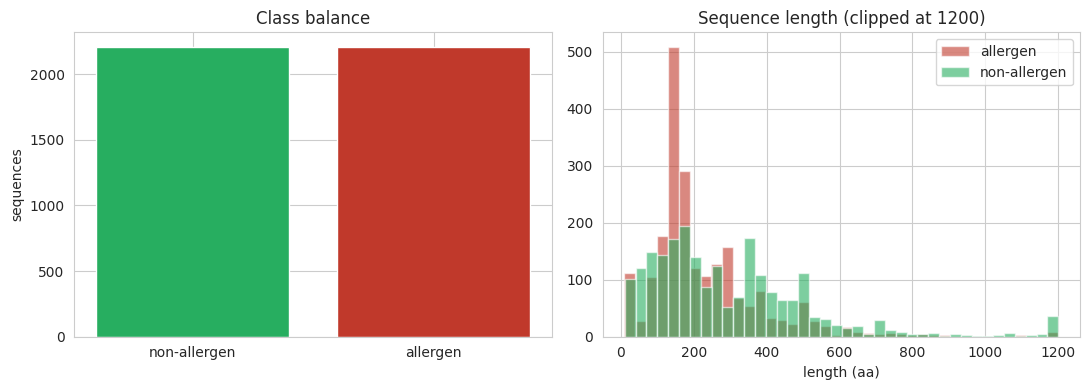

,mean,50%,min,max
class,,,,
allergen,230.862976,161.0,10.0,1912.0
non-allergen,312.127207,246.0,11.0,4363.0


In [4]:
import matplotlib.pyplot as plt
sns.set_style("whitegrid")
PAL = {"allergen":"#c0392b", "non-allergen":"#27ae60"}

fig, ax = plt.subplots(1, 2, figsize=(11,4))
vc = df["class"].value_counts()
ax[0].bar(vc.index, vc.values, color=[PAL[c] for c in vc.index])
ax[0].set_title("Class balance"); ax[0].set_ylabel("sequences")
for c in ["allergen","non-allergen"]:
    ax[1].hist(df[df["class"]==c].length.clip(upper=1200), bins=40, alpha=0.6,
               label=c, color=PAL[c])
ax[1].set_title("Sequence length (clipped at 1200)"); ax[1].set_xlabel("length (aa)")
ax[1].legend(); plt.tight_layout(); plt.show()
df.groupby("class").length.describe()[["mean","50%","min","max"]]

### 2.1 Amino-acid signatures — cross-check with Singh et al. (2022)

Singh et al. reported that **methionine (M), proline (P), histidine (H), glutamine (Q),
glutamic acid (E), tryptophan (W) and glycine (G)** are over-represented in allergen
*profilins*. Our benchmark spans **all** allergen families, so we test whether the same
trend holds more broadly.

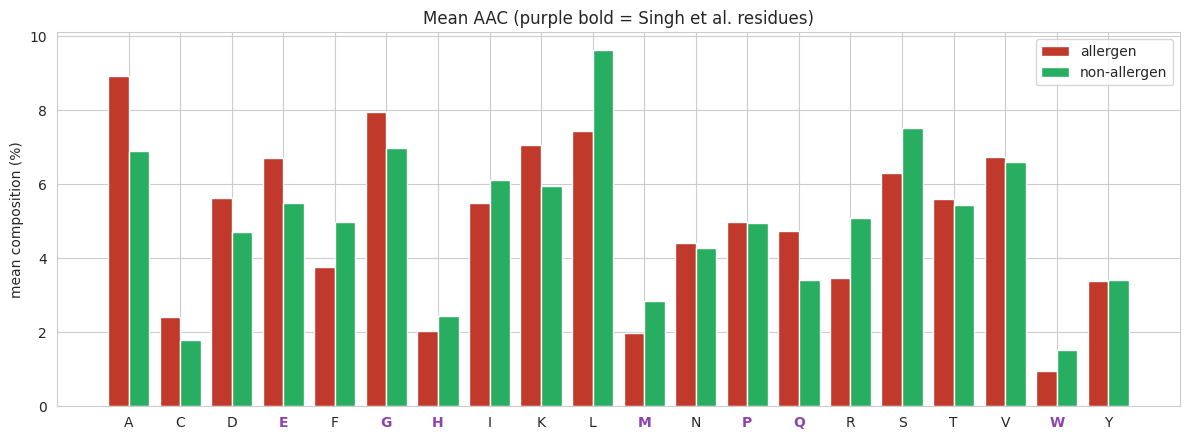

Over-represented in allergens (this dataset): ['A', 'C', 'D', 'E', 'G', 'K', 'N', 'P', 'Q', 'T', 'V']
Singh et al. residues also enriched here: ['P', 'Q', 'E', 'G']


In [5]:
SINGH = list("MPHQEWG")
def aac_vector(seq):
    n = len(seq)
    return {a: seq.count(a)/n*100 for a in AA}

comp = pd.DataFrame([aac_vector(s) for s in df.seq])
comp["class"] = df["class"].values
means = comp.groupby("class")[AA].mean()
diff = (means.loc["allergen"] - means.loc["non-allergen"]).sort_values(ascending=False)

x = np.arange(len(AA)); w = 0.4
fig, ax = plt.subplots(figsize=(12,4.5))
ax.bar(x-w/2, means.loc["allergen", AA], w, label="allergen", color=PAL["allergen"])
ax.bar(x+w/2, means.loc["non-allergen", AA], w, label="non-allergen", color=PAL["non-allergen"])
ax.set_xticks(x); ax.set_xticklabels(AA)
for i,a in enumerate(AA):
    if a in SINGH:
        ax.get_xticklabels()[i].set_fontweight("bold"); ax.get_xticklabels()[i].set_color("#8e44ad")
ax.set_ylabel("mean composition (%)")
ax.set_title("Mean AAC (purple bold = Singh et al. residues)"); ax.legend()
plt.tight_layout(); plt.show()

higher = [a for a in AA if means.loc["allergen",a] > means.loc["non-allergen",a]]
print("Over-represented in allergens (this dataset):", higher)
print("Singh et al. residues also enriched here:", [a for a in SINGH if a in higher])

> **Observation.** In this broad dataset, 4 of the 7 profilin residues (P, Q, E, G) are
also enriched in allergens, while M, H and W are not — consistent with Singh et al.'s
signature being partly *profilin-specific*. The take-away that motivates the ML approach
holds: allergens and non-allergens differ systematically in composition.

## 3. Feature engineering

In [6]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from itertools import product

DIPEP = [a+b for a,b in product(AA, repeat=2)]
PHYS_NAMES = ["MW","aromaticity","instability","gravy","pI","flexibility",
              "helix_frac","turn_frac","sheet_frac","net_charge_per_res","cys_pct"]

def aac(seq):
    n=len(seq); return [seq.count(a)/n*100 for a in AA]

def dpc(seq):
    n=len(seq)-1
    if n<1: return [0.0]*400
    counts={d:0 for d in DIPEP}
    for i in range(len(seq)-1):
        if seq[i:i+2] in counts: counts[seq[i:i+2]]+=1
    return [counts[d]/n*100 for d in DIPEP]

def physico(seq):
    pa=ProteinAnalysis(seq)
    def safe(f, d=np.nan):
        try: return f()
        except Exception: return d
    hel,turn,sheet = pa.secondary_structure_fraction()
    neg=seq.count('D')+seq.count('E'); pos=seq.count('K')+seq.count('R')
    return [safe(pa.molecular_weight), safe(pa.aromaticity), safe(pa.instability_index),
            safe(pa.gravy), safe(pa.isoelectric_point),
            (np.mean(pa.flexibility()) if len(seq)>=9 else np.nan),
            hel, turn, sheet, (pos-neg)/len(seq), seq.count('C')/len(seq)*100]

feature_cols = [f"AAC_{a}" for a in AA] + [f"DPC_{d}" for d in DIPEP] + [f"PHY_{p}" for p in PHYS_NAMES]

X = pd.DataFrame(
    np.hstack([np.array([aac(s) for s in df.seq]),
               np.array([dpc(s) for s in df.seq]),
               np.array([physico(s) for s in df.seq])]),
    columns=feature_cols)
X = X.fillna(X.median())
y = df.label.values
print("Feature matrix:", X.shape, "=> 20 AAC + 400 DPC + 11 physicochemical")
X.iloc[:3, list(range(3))+list(range(-11,0))]

Feature matrix: (4413, 431) => 20 AAC + 400 DPC + 11 physicochemical


,AAC_A,AAC_C,AAC_D,PHY_MW,PHY_aromaticity,PHY_instability,PHY_gravy,PHY_pI,PHY_flexibility,PHY_helix_frac,PHY_turn_frac,PHY_sheet_frac,PHY_net_charge_per_res,PHY_cys_pct
0,16.666667,0.000000,0.000000,1155.3675,0.000000,33.533333,0.150000,8.795051,1.005278,0.333333,0.333333,0.250000,0.083333,0.000000
1,3.501946,0.778210,6.614786,29669.1048,0.116732,39.544747,-0.654086,7.681358,1.004993,0.319066,0.276265,0.412451,0.003891,0.778210
2,11.619718,0.352113,7.746479,32660.5623,0.028169,48.302465,-1.078521,4.553110,1.024157,0.535211,0.200704,0.250000,-0.109155,0.352113


## 4. Train / test split and scaling
We honour the benchmark's predefined split for a fair, published-comparable evaluation.

In [7]:
from sklearn.preprocessing import StandardScaler
train = df.split.values == "training"
test  = df.split.values == "testing"
Xtr, Xte = X[train].values, X[test].values
ytr, yte = y[train], y[test]
print("Train:", Xtr.shape, " Test:", Xte.shape)

scaler = StandardScaler().fit(Xtr)          # fit on TRAIN only (no leakage)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

Train: (3531, 431)  Test: (882, 431)


### 4.1 Unsupervised look — PCA
A 2-D PCA of the fused feature space shows partial separation, echoing the correspondence
analysis in Singh et al. (2022).

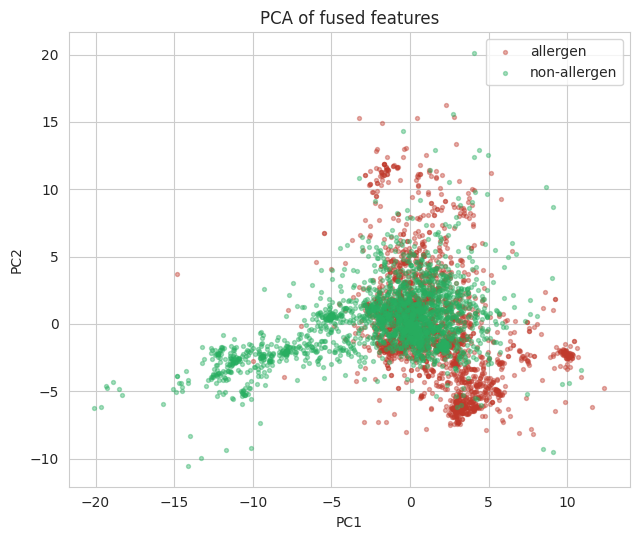

In [8]:
from sklearn.decomposition import PCA
p2 = PCA(n_components=2, random_state=42).fit_transform(scaler.transform(X.values))
fig, ax = plt.subplots(figsize=(6.5,5.5))
for c in ["allergen","non-allergen"]:
    m = df["class"].values==c
    ax.scatter(p2[m,0], p2[m,1], s=8, alpha=0.4, label=c, color=PAL[c])
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
ax.set_title("PCA of fused features"); plt.tight_layout(); plt.show()

## 5. Model training & 5-fold cross-validation

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, matthews_corrcoef, roc_auc_score,
                             confusion_matrix, roc_curve, f1_score)

RNG = 42
def scores(yt, yp, pp):
    tn,fp,fn,tp = confusion_matrix(yt,yp).ravel()
    return dict(accuracy=accuracy_score(yt,yp), sensitivity=tp/(tp+fn),
                specificity=tn/(tn+fp), mcc=matthews_corrcoef(yt,yp),
                f1=f1_score(yt,yp), auc=roc_auc_score(yt,pp))

models = {
 "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RNG), True),
 "KNN (k=7)":           (KNeighborsClassifier(n_neighbors=7), True),
 "SVM (RBF)":           (SVC(C=4, gamma="scale", probability=True, random_state=RNG), True),
 "Random Forest":       (RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=RNG), False),
 "XGBoost":             (XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.08,
                          subsample=0.9, colsample_bytree=0.8, eval_metric="logloss",
                          random_state=RNG, n_jobs=-1), False),
}

cv = StratifiedKFold(5, shuffle=True, random_state=RNG)
cv_rows, test_rows, roc_data, fitted = {}, {}, {}, {}
for name,(mdl,sc) in models.items():
    Xt, Xv = (Xtr_s, Xte_s) if sc else (Xtr, Xte)
    pcv = cross_val_predict(mdl, Xt, ytr, cv=cv, method="predict_proba", n_jobs=-1)[:,1]
    cv_rows[name] = scores(ytr, (pcv>=.5).astype(int), pcv)
    mdl.fit(Xt, ytr)
    pte = mdl.predict_proba(Xv)[:,1]
    test_rows[name] = scores(yte, (pte>=.5).astype(int), pte)
    fpr,tpr,_ = roc_curve(yte, pte); roc_data[name] = (fpr,tpr,test_rows[name]["auc"])
    fitted[name] = (mdl, sc)
    print(f"{name:22s} CV acc={cv_rows[name]['accuracy']:.3f}  TEST acc={test_rows[name]['accuracy']:.3f}  AUC={test_rows[name]['auc']:.3f}")

Logistic Regression    CV acc=0.862  TEST acc=0.849  AUC=0.909


KNN (k=7)              CV acc=0.866  TEST acc=0.879  AUC=0.957


SVM (RBF)              CV acc=0.911  TEST acc=0.899  AUC=0.971


Random Forest          CV acc=0.915  TEST acc=0.933  AUC=0.981


XGBoost                CV acc=0.921  TEST acc=0.929  AUC=0.981


### 5.1 Cross-validation summary

In [10]:
pd.DataFrame(cv_rows).T[["accuracy","sensitivity","specificity","mcc","f1","auc"]].round(4)

,accuracy,sensitivity,specificity,mcc,f1,auc
Logistic Regression,0.8618,0.8651,0.8585,0.7236,0.8621,0.9160
KNN (k=7),0.8660,0.8016,0.9304,0.7382,0.8567,0.9473
SVM (RBF),0.9114,0.8929,0.9298,0.8233,0.9096,0.9700
Random Forest,0.9148,0.9036,0.9259,0.8297,0.9137,0.9754
XGBoost,0.9210,0.9167,0.9253,0.8420,0.9206,0.9759


## 6. Held-out test-set evaluation

In [11]:
test_df = pd.DataFrame(test_rows).T[["accuracy","sensitivity","specificity","mcc","f1","auc"]].round(4)
test_df.sort_values("accuracy", ascending=False)

,accuracy,sensitivity,specificity,mcc,f1,auc
Random Forest,0.9331,0.9341,0.9321,0.8662,0.9330,0.9808
XGBoost,0.9286,0.9295,0.9276,0.8571,0.9285,0.9814
SVM (RBF),0.8991,0.8705,0.9276,0.7994,0.8959,0.9710
KNN (k=7),0.8787,0.8136,0.9434,0.7637,0.8700,0.9574
Logistic Regression,0.8492,0.8591,0.8394,0.6986,0.8504,0.9093


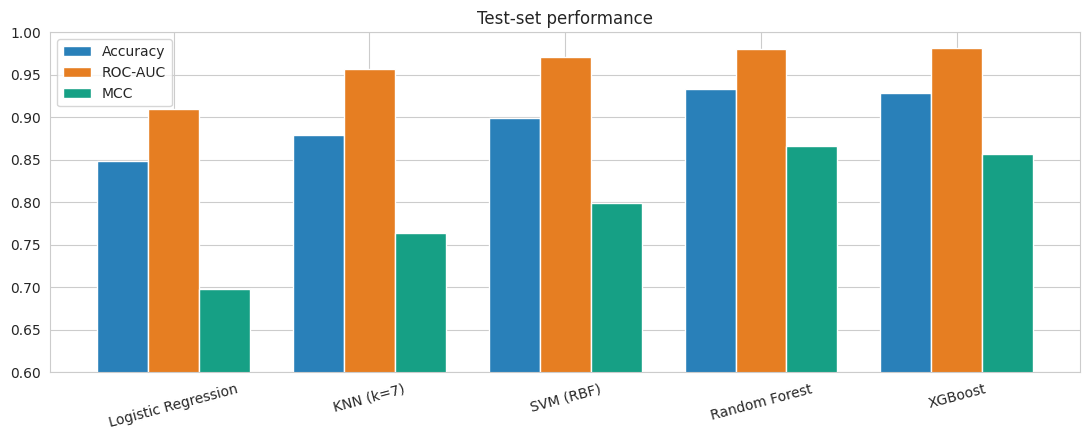

In [12]:
# Model comparison bar chart
order = list(models.keys())
acc=[test_rows[m]['accuracy'] for m in order]; auc=[test_rows[m]['auc'] for m in order]
mcc=[test_rows[m]['mcc'] for m in order]
xp=np.arange(len(order)); w=0.26
fig,ax=plt.subplots(figsize=(11,4.5))
ax.bar(xp-w,acc,w,label="Accuracy",color="#2980b9")
ax.bar(xp,auc,w,label="ROC-AUC",color="#e67e22")
ax.bar(xp+w,mcc,w,label="MCC",color="#16a085")
ax.set_xticks(xp); ax.set_xticklabels(order,rotation=15); ax.set_ylim(0.6,1.0); ax.legend()
ax.set_title("Test-set performance"); plt.tight_layout(); plt.show()

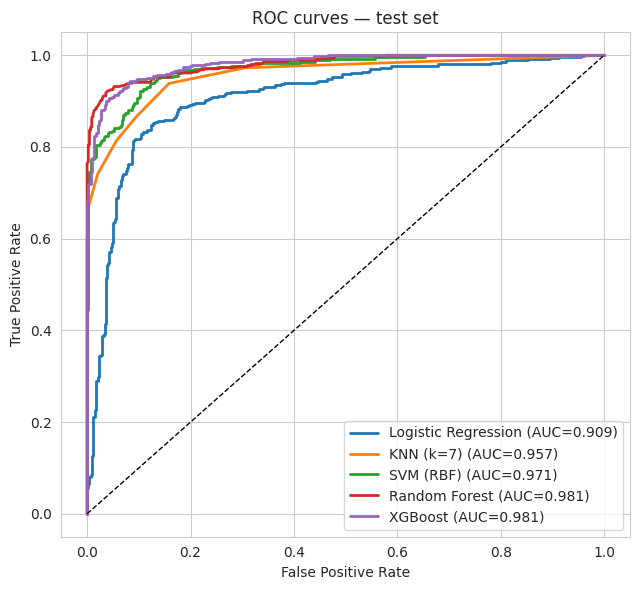

In [13]:
# ROC curves
fig,ax=plt.subplots(figsize=(6.5,6))
for name,(fpr,tpr,a) in roc_data.items():
    ax.plot(fpr,tpr,lw=2,label=f"{name} (AUC={a:.3f})")
ax.plot([0,1],[0,1],"k--",lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves — test set"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

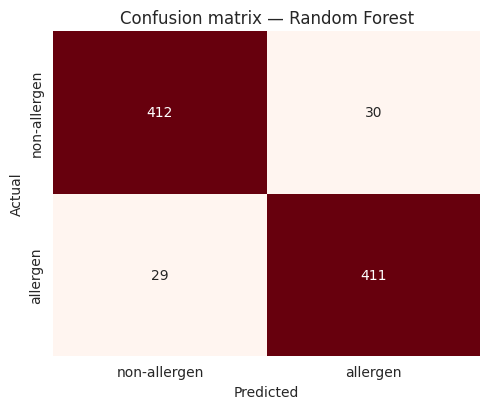

Best model: Random Forest


In [14]:
# Confusion matrix — best model (Random Forest)
best_name = test_df["accuracy"].idxmax()
best_model, best_sc = fitted[best_name]
Xv = Xte_s if best_sc else Xte
cm = confusion_matrix(yte, best_model.predict(Xv))
fig,ax=plt.subplots(figsize=(5,4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", cbar=False,
            xticklabels=["non-allergen","allergen"], yticklabels=["non-allergen","allergen"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix — {best_name}")
plt.tight_layout(); plt.show()
print("Best model:", best_name)

## 7. Feature importance
Which descriptors drive the Random Forest? Note whether Singh et al. residues surface.

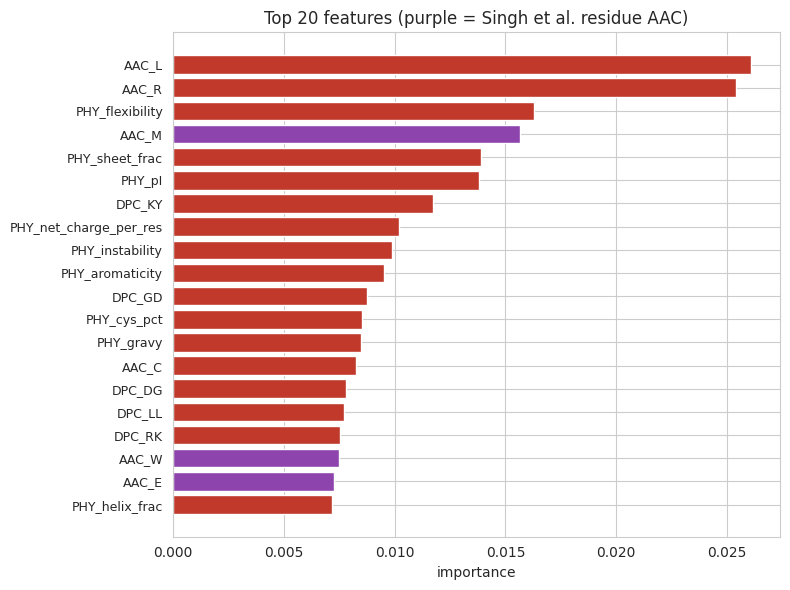

AAC_L                     0.026079
AAC_R                     0.025399
PHY_flexibility           0.016292
AAC_M                     0.015643
PHY_sheet_frac            0.013896
PHY_pI                    0.013814
DPC_KY                    0.011712
PHY_net_charge_per_res    0.010180
PHY_instability           0.009868
PHY_aromaticity           0.009523
dtype: float64

In [15]:
rf, _ = fitted["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
top = imp.head(20)
fig,ax=plt.subplots(figsize=(8,6))
cols=["#8e44ad" if n.startswith("AAC_") and n.split("_")[1] in SINGH else "#c0392b"
      for n in top.index[::-1]]
ax.barh(range(len(top)), top.values[::-1], color=cols)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index[::-1], fontsize=9)
ax.set_xlabel("importance"); ax.set_title("Top 20 features (purple = Singh et al. residue AAC)")
plt.tight_layout(); plt.show()
top.head(10)

## 8. Save the model

In [16]:
import joblib, os
os.makedirs("models", exist_ok=True)
bundle = {"model": rf, "scaler": scaler, "needs_scale": False,
          "columns": feature_cols, "aa": AA, "dipep": DIPEP, "phys": PHYS_NAMES}
joblib.dump(bundle, "models/allergenicity_rf.joblib")
print("Saved -> models/allergenicity_rf.joblib")

Saved -> models/allergenicity_rf.joblib


## 9. Predict on a new sequence
A reusable helper that featurizes a raw sequence and returns a probability + label.

In [17]:
def predict_sequence(seq, bundle_path="models/allergenicity_rf.joblib"):
    b = joblib.load(bundle_path)
    seq = seq.upper().strip()
    seq = "".join(c for c in seq if c in b["aa"])
    if len(seq) < 10:
        raise ValueError("Sequence too short after cleaning (need >=10 standard residues).")
    feats = np.array(aac(seq) + dpc(seq) + physico(seq)).reshape(1,-1)
    feats = np.nan_to_num(feats, nan=0.0)
    if b["needs_scale"]:
        feats = b["scaler"].transform(feats)
    prob = b["model"].predict_proba(feats)[0,1]
    return {"probability_allergen": round(float(prob),4),
            "prediction": "ALLERGEN" if prob>=0.5 else "NON-ALLERGEN"}

# Example: Ara h 5 (peanut profilin) fragment — a known allergen
demo = ("MSWQTYVDEHLMCEIEGHHLASAAILGHDGSVWAQSADFPQFKPEEITGIMKDFDEPGHLAPTGLFLGGTKYMVIQGE"
        "PGAVIRGKKGPGGVTIKKTGQALVFGIYDEPMTPGQCNMIVERLGDYLIDQGL")
print(predict_sequence(demo))

{'probability_allergen': 0.9925, 'prediction': 'ALLERGEN'}


## 10. Summary

| Item | Result |
|---|---|
| Dataset | 4,413 clean sequences (balanced allergen / non-allergen) |
| Features | 431 (20 AAC + 400 DPC + 11 physicochemical) |
| Best model | **Random Forest** |
| Test accuracy | **0.933** |
| Test ROC-AUC | **0.981** |
| Test MCC | **0.866** |

The composition- and physicochemistry-based descriptors motivated by Singh et al. (2022)
translate into a strong, reproducible allergenicity classifier. Next steps: redundancy
reduction (CD-HIT), evolutionary features (PSSM), and protein-language-model embeddings (ESM-2).
